# Lab 6 – ARTI403
Frequency-domain filtering of the Cameraman image

## Task 1: Laplacian filter in the frequency domain

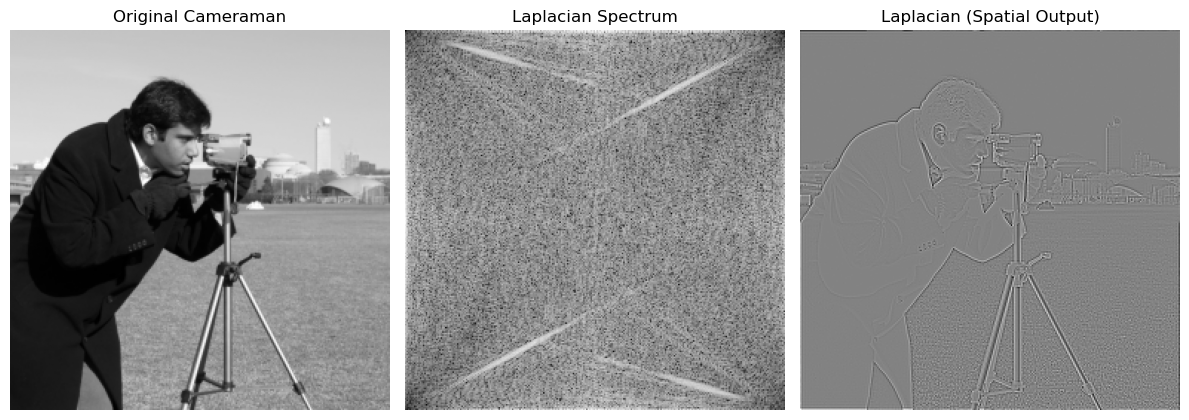

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()


## Task 2: Sobel filters in the frequency domain
Same Cameraman image, now filtered with the Sobel-X and Sobel-Y kernels by multiplying in the frequency domain.

### Step 1: Imports, load and resize the image

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import data
from skimage.transform import resize

# Load and resize image
image = data.camera()
image = resize(image, (256, 256))
print("Image shape:", image.shape)

Image shape: (256, 256)


### Step 2: Define the Sobel filters

In [3]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

### Step 3: Pad and center the kernel, then take its FFT
`ifftshift` moves the kernel center to index (0,0) before the FFT, so the filter has no unwanted phase shift.

In [4]:
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

### Step 4: Compute the FFT of the image and of the Sobel filters

In [5]:
F = fft2(image)

Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

### Step 5: Multiply in the frequency domain and inverse FFT

In [6]:
Gx_f = F * Hx
Gy_f = F * Hy

gx = ifft2(Gx_f).real
gy = ifft2(Gy_f).real
magnitude = np.sqrt(gx**2 + gy**2)

### Step 6: Plot the results

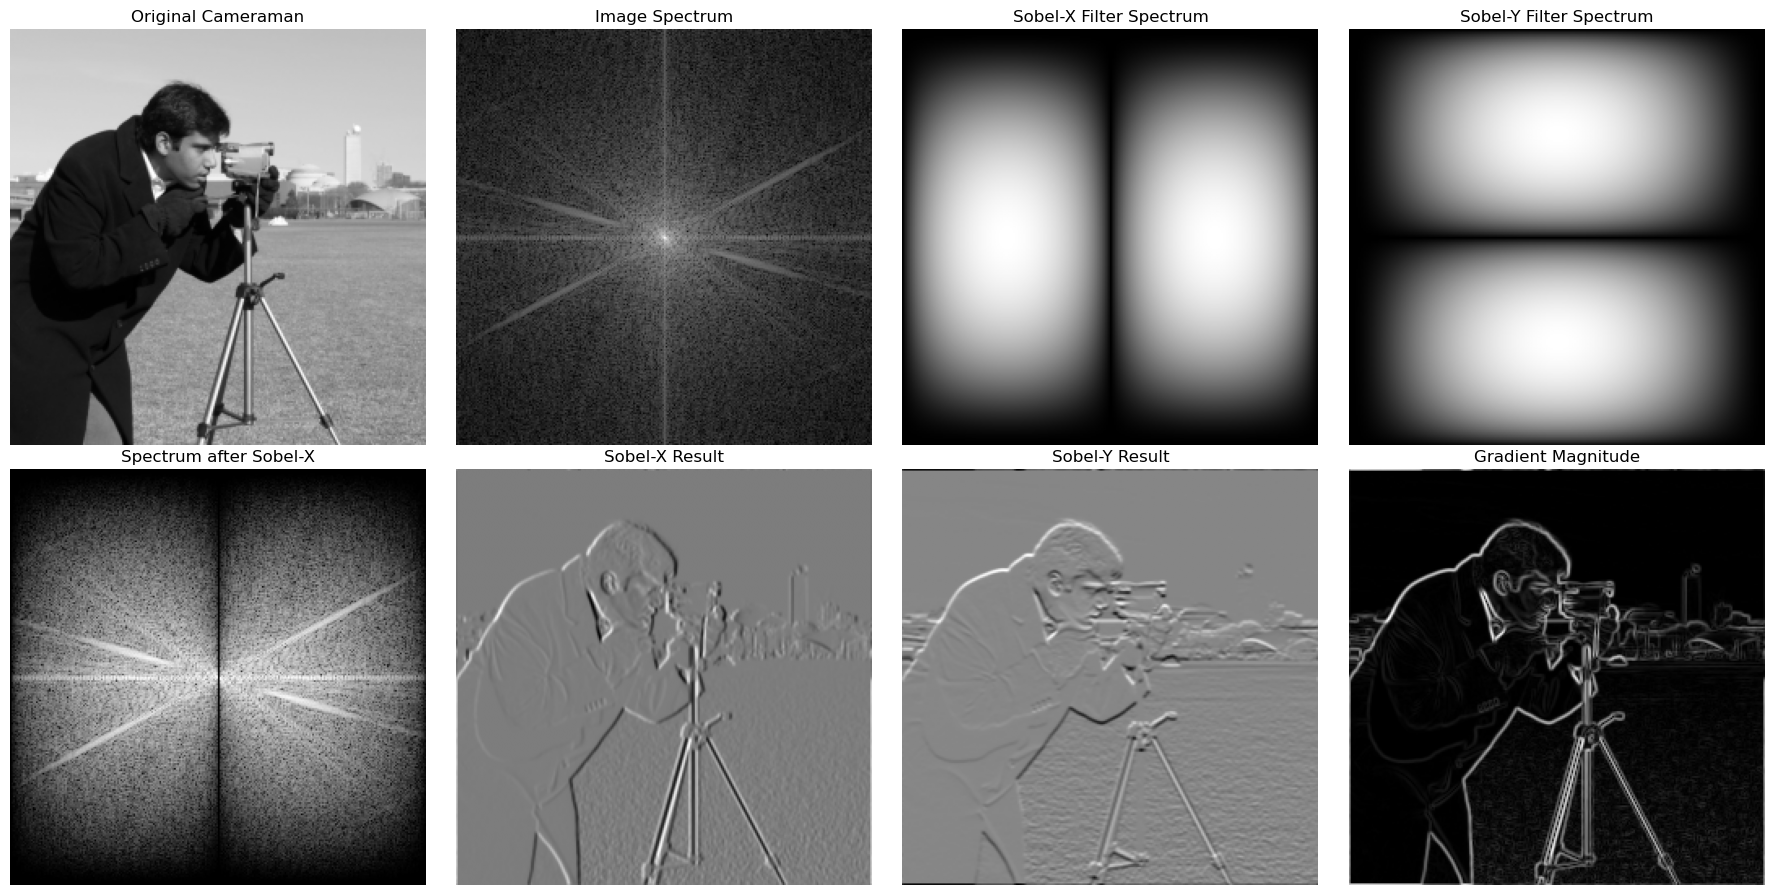

In [7]:
spec = lambda X: np.log(1 + np.abs(fftshift(X)))

fig, ax = plt.subplots(2, 4, figsize=(18, 9))
ax[0,0].imshow(image, cmap='gray');        ax[0,0].set_title('Original Cameraman')
ax[0,1].imshow(spec(F), cmap='gray');      ax[0,1].set_title('Image Spectrum')
ax[0,2].imshow(spec(Hx), cmap='gray');     ax[0,2].set_title('Sobel-X Filter Spectrum')
ax[0,3].imshow(spec(Hy), cmap='gray');     ax[0,3].set_title('Sobel-Y Filter Spectrum')
ax[1,0].imshow(spec(Gx_f), cmap='gray');   ax[1,0].set_title('Spectrum after Sobel-X')
ax[1,1].imshow(gx, cmap='gray');           ax[1,1].set_title('Sobel-X Result')
ax[1,2].imshow(gy, cmap='gray');           ax[1,2].set_title('Sobel-Y Result')
ax[1,3].imshow(magnitude, cmap='gray');    ax[1,3].set_title('Gradient Magnitude')
for a in ax.ravel(): a.axis('off')
plt.tight_layout()
plt.show()

### Observations
- **Sobel-X** responds to horizontal intensity changes, so it highlights vertical edges (tripod legs, coat outline).
- **Sobel-Y** responds to vertical intensity changes, so it highlights horizontal edges (horizon, camera body).
- **Gradient magnitude** combines both into a single edge map.
- Both filter spectra suppress low frequencies and peak at mid frequencies: edge detection with built-in smoothing.
- Multiplying FFTs is circular convolution, so slight wrap-around artifacts can appear at the image borders.